# 01 — Dataset and train/test split

The goal of this notebook is one decision: **which notes are used for training and which for testing.**

The main risk is leakage. Each NSynth instrument is recorded at up to 88 pitches × 5 velocities = 440 notes, and
two notes of the same instrument a semitone apart are almost the same sound. If notes are split at random, the test set
is full of near-copies of training notes, and the model can score well just by recognising *the instrument* rather than
*the family*. (Same idea as not putting frames of the same video in both train and test in computer vision.)

So the split is **grouped by instrument**: all notes of an instrument go to one side.

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "..")
from src.dataset import SPLIT_FILE, load_metadata, load_notes

notes = load_metadata()
notes["nsynth_split"] = ["valid" if "nsynth-valid" in str(p) else "test" for p in notes["path"]]
print(f"{len(notes)} notes, {notes['instrument'].nunique()} instruments, {notes['family'].nunique()} families")
notes.drop(columns="path").head()

16774 notes, 53 instruments, 10 families


,note,instrument,family,source,pitch,velocity,nsynth_split
0,keyboard_acoustic_004-060-025,keyboard_acoustic_004,keyboard,acoustic,60,25,valid
1,bass_synthetic_033-050-100,bass_synthetic_033,bass,synthetic,50,100,valid
2,bass_synthetic_009-052-050,bass_synthetic_009,bass,synthetic,52,50,valid
3,keyboard_electronic_003-064-127,keyboard_electronic_003,keyboard,electronic,64,127,valid
4,bass_synthetic_034-030-050,bass_synthetic_034,bass,synthetic,30,50,valid


## 1. The official NSynth splits can't be used as train/test here

I only use the `valid` and `test` folders (the 23.8 GB `train` folder is too much for my hardware).
The obvious idea would be "train on `valid`, test on `test`". But checking which instruments are in each:

In [2]:
valid_instr = set(notes.loc[notes["nsynth_split"] == "valid", "instrument"])
test_instr = set(notes.loc[notes["nsynth_split"] == "test", "instrument"])
print(f"instruments in valid: {len(valid_instr)}, in test: {len(test_instr)}, in both: {len(valid_instr & test_instr)}")

instruments in valid: 53, in test: 53, in both: 53


**Every instrument is in both.** NSynth's own `valid`/`test` were built to be evaluated against the much larger `train`
split, not against each other. Using them as train/test would be exactly the leakage described above.

So I pool the two folders into one set of 53 instruments and make my own split.

## 2. What is in the pool

53 instruments is not much. Some families have only 2 or 3 instruments:

In [3]:
per_family = notes.groupby("family").agg(instruments=("instrument", "nunique"), notes=("note", "size"))
per_family

,instruments,notes
family,,
bass,10,3481
brass,5,1155
flute,2,650
guitar,7,2733
keyboard,8,3170
mallet,3,865
organ,6,2100
reed,4,955
string,6,1120


The families are also not balanced in **how the sound was produced** (acoustic recording, electronic instrument,
or software synthesizer):

In [4]:
pd.crosstab(notes["family"], notes["source"])

source,acoustic,electronic,synthetic
family,,,
bass,0,630,2851
brass,1155,0,0
flute,210,0,440
guitar,1963,770,0
keyboard,440,2290,440
mallet,865,0,0
organ,0,2100,0
reed,955,0,0
string,1120,0,0


Organ is 100% electronic; brass, mallet, reed and string are 100% acoustic. So "family" and "source" are partly the
same label. A model might learn "this sounds synthetic" instead of "this is an organ". I can't fix this with this
data, but I need to remember it when analysing errors in Phase 4.

Another possible shortcut is **pitch**: if a family only played low notes, the model could learn pitch instead of timbre.

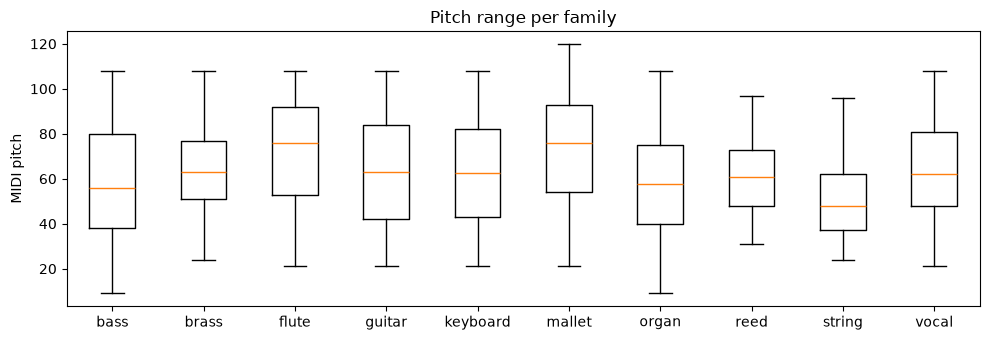

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.5))
families = sorted(notes["family"].unique())
ax.boxplot([notes.loc[notes["family"] == f, "pitch"] for f in families], tick_labels=families)
ax.set(title="Pitch range per family", ylabel="MIDI pitch")
plt.tight_layout()

The ranges overlap a lot (most families cover roughly MIDI 21–108, the piano range), so pitch alone shouldn't be
a strong shortcut. The medians do differ (string is lower, flute and mallet higher), so it carries *some* information.

## 3. The split: one instrument per family goes to test

The simplest rule that guarantees every family appears in both train and test: for each family, pick **one instrument
at random** (fixed seed) and put all its notes in test. Everything else is train.

The choice is made once by `python -m src.dataset` and saved in `splits/instruments.csv` (53 rows, versioned in git),
so every later phase uses exactly the same split.

In [6]:
notes = load_notes()  # metadata + the saved split
split_table = pd.read_csv(SPLIT_FILE)
split_table[split_table["split"] == "test"]

,instrument,family,source,n_notes,split
8,bass_synthetic_134,bass,synthetic,440,test
13,brass_acoustic_046,brass,acoustic,285,test
16,flute_synthetic_000,flute,synthetic,440,test
18,guitar_acoustic_014,guitar,acoustic,440,test
26,keyboard_electronic_002,keyboard,electronic,440,test
32,mallet_acoustic_047,mallet,acoustic,220,test
35,organ_electronic_001,organ,electronic,305,test
41,reed_acoustic_011,reed,acoustic,215,test
46,string_acoustic_014,string,acoustic,210,test
52,vocal_synthetic_003,vocal,synthetic,440,test


In [7]:
# The property the split exists for: no instrument on both sides.
train_instr = set(notes.loc[notes["split"] == "train", "instrument"])
test_instr = set(notes.loc[notes["split"] == "test", "instrument"])
assert not (train_instr & test_instr)

counts = pd.crosstab(notes["family"], notes["split"])
counts["test %"] = (100 * counts["test"] / counts.sum(axis=1)).round(0)
print(f"train: {(notes['split'] == 'train').sum()} notes, {len(train_instr)} instruments")
print(f"test:  {(notes['split'] == 'test').sum()} notes, {len(test_instr)} instruments")
counts

train: 13339 notes, 43 instruments
test:  3435 notes, 10 instruments


split,test,train,test %
family,,,
bass,440,3041,13.0
brass,285,870,25.0
flute,440,210,68.0
guitar,440,2293,16.0
keyboard,440,2730,14.0
mallet,220,645,25.0
organ,305,1795,15.0
reed,215,740,23.0
string,210,910,19.0


## 4. Limitations (honest list)

- **The test set is small in the way that matters.** 3,435 notes sounds like a lot, but it is only **10 instruments**.
  The result for each family is really the result on *one* instrument. A different seed could give quite different
  per-family numbers. I'll keep the seed fixed and not tune anything on the test set.
- **Flute and vocal will be hard, by construction.** Each has two instruments, one acoustic and one synthetic.
  The test got the synthetic one, so the model trains on acoustic flute/vocal only (210 and 105 notes) and is
  tested on synthetic (440 notes each) — for these two families, most of the notes are in test (68% and 81%). Low scores there will say more about the data than about the model.
- **Classes are unbalanced** (bass has ~6× more notes than vocal). Plain accuracy would hide this, so the
  evaluation will use per-class recall and balanced accuracy.
- **No separate validation set yet.** If the CNN in Phase 3 needs one (e.g. to choose the number of epochs),
  it has to come out of the train instruments, also grouped by instrument. I'll decide that in Phase 3.